<a href="https://colab.research.google.com/github/karsarobert/DeepLearning2026/blob/main/PTE_DL8_FE_javitott.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning gyakorlat


## 7. gyakorlat: transfer learning
### 2026. november 2.

forrás: https://github.com/mrdbourke/tensorflow-deep-learning

#transfer learning, feature extraction

Építettünk egy csomó konvolúciós neurális hálózatot a semmiből, és úgy tűnik, hogy mind tanulnak, azonban még mindig rengeteg lehetőség van a fejlődésre.

A modell(ek) javításához eltölthetünk egy kis időt különböző konfigurációk kipróbálásával, több réteg hozzáadásával, a tanulási sebesség megváltoztatásával, a rétegenkénti neuronok számának beállításával és még sok mással.

Ennek elvégzése azonban nagyon időigényes.

Szerencsére van egy technika, amellyel időt takaríthatunk meg.

Ezt **transzfer-tanulásnak** hívják, más szóval, egy másik modell által egy másik problémából megtanult mintákat (más néven súlyokat) veszünk, és felhasználjuk a saját problémánkhoz.

A transzfer tanulás alkalmazásának két fő előnye van:
1. Felhasználhatunk egy meglévő neurális hálózati architektúrát, amely bizonyítottan működik a miénkhez hasonló problémákon.
2. Olyan működő neurális hálózati architektúrát használhatunk fel, amely **már megtanult** mintákat a miénkhez hasonló adatokon. Ez gyakran azt eredményezi, hogy kevesebb egyedi adattal is nagyszerű eredményeket érhetünk el.

Ez azt jelenti, hogy ahelyett, hogy saját neurális hálózati architektúrát készítenénk vagy a semmiből építenénk, felhasználhatunk olyan modelleket, amelyek másoknál már beváltak.

Ahelyett pedig, hogy a saját modelljeinket a semmiből képeznénk ki saját adathalmazainkon, az olyan adathalmazokból, mint például az [ImageNet](http://www.image-net.org/) (több millió különböző tárgyat ábrázoló kép) tanult mintákat vehetjük alapul, és használhatjuk azokat a saját modelljeink alapjául. Ha így járunk el, gyakran kevesebb adatból is nagyszerű eredményeket érhetünk el.


In [ ]:
import os
# Keras 2 kompatibilitás beállítása a tensorflow_hub.KerasLayer támogatásához (TF 2.16+ esetén)
os.environ['TF_USE_LEGACY_KERAS'] = '1'


## GPU használata

Először is ellenőrizzük, hogy használunk-e GPU-t. A GPU használata biztosítja, hogy a modellünk gyorsabban edződjön, mintha csak a CPU-t használnánk.


In [ ]:
# Are we using a GPU?
!nvidia-smi

Sun Nov  1 08:38:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Ha a fenti cella nem ad ki valamit, ami úgy néz ki, mint:

```
Fri Sep  4 03:35:21 2020       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 450.66       Driver Version: 418.67       CUDA Version: 10.1     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  Tesla P100-PCIE...  Off  | 00000000:00:04.0 Off |                    0 |
| N/A   35C    P0    26W / 250W |      0MiB / 16280MiB |      0%      Default |
|                               |                      |                 ERR! |
+-------------------------------+----------------------+----------------------+
                                                                               
+-----------------------------------------------------------------------------+
| Processes:                                                                  |
|  GPU   GI   CI        PID   Type   Process name                  GPU Memory |
|        ID   ID                                                   Usage      |
|=============================================================================|
|  No running processes found                                                 |
+-----------------------------------------------------------------------------+
```

Menj a Futtatókörnyezet -> Futtatókörnyezet módosítása -> Hardveres gyorsítás és válaszd a "GPU" lehetőséget, majd futtasd újra a fenti cellát.

## Transfer learning (transzfer tanulás) Kaggle Models és TensorFlow Hub segítségével: Nagyszerű eredmények elérése az adatok 10%-ával

Sok olyan problémára, amelyre a mélytanulást szeretné használni, jó eséllyel már létezik egy működő modell.

A korábbi **TensorFlow Hub (tfhub.dev)** teljes egészében beolvadt a **[Kaggle Models](https://www.kaggle.com/models)** platformba. Ez teszi lehetővé, hogy egy teljesen betanított modellt importálhasson és használhasson egy Kaggle Models URL vagy a `kagglehub` könyvtár segítségével.

Mi lenne, ha az eredeti adatok mindössze 10%-ával, vagyis 10-szer kevesebb adattal is nagyjából ugyanazokat az eredményeket (vagy jobbakat) kaphatnánk, mint amit a saját építésű modellünk eddig elért?

**A transzfer tanulás gyakran lehetővé teszi, hogy kevesebb adattal is nagyszerű eredményeket érjünk el.**

Töltsük le az általunk használt adatok egy részhalmazát, nevezetesen a `10_food_classes` adathalmaz képzési adatainak 10%-át, és használjuk azt egy ételkép-osztályozó betanítására.

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/04-transfer-learning-feature-extraction.png)


## Adatok letöltése

In [ ]:
# Get data (10% of labels)
import zipfile

# Download data
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip

# Unzip the downloaded file
zip_ref = zipfile.ZipFile("10_food_classes_10_percent.zip", "r")
zip_ref.extractall()
zip_ref.close()

--2026-11-01 08:38:35--  https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 104.154.124.27, 104.154.125.27, 34.144.171.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|104.154.124.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 168546183 (161M) [application/zip]
Saving to: ‘10_food_classes_10_percent.zip’

10_food_classes_10_ 100%[===================>] 160.74M   178MB/s    in 0.9s    

2026-11-01 08:38:36 (178 MB/s) - ‘10_food_classes_10_percent.zip’ saved [168546183/168546183]



In [ ]:
# Hány kép van az egyes mappákban?
import os

# Menjünk végig a 10 százalékos adatkönyvtáron
for dirpath, dirnames, filenames in os.walk("10_food_classes_10_percent"):
  print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

There are 2 directories and 0 images in '10_food_classes_10_percent'.
There are 10 directories and 0 images in '10_food_classes_10_percent/test'.
There are 0 directories and 250 images in '10_food_classes_10_percent/test/grilled_salmon'.
There are 0 directories and 250 images in '10_food_classes_10_percent/test/fried_rice'.
There are 0 directories and 250 images in '10_food_classes_10_percent/test/ice_cream'.
There are 0 directories and 250 images in '10_food_classes_10_percent/test/ramen'.
There are 0 directories and 250 images in '10_food_classes_10_percent/test/sushi'.
There are 0 directories and 250 images in '10_food_classes_10_percent/test/hamburger'.
There are 0 directories and 250 images in '10_food_classes_10_percent/test/chicken_wings'.
There are 0 directories and 250 images in '10_food_classes_10_percent/test/chicken_curry'.
There are 0 directories and 250 images in '10_food_classes_10_percent/test/pizza'.
There are 0 directories and 250 images in '10_food_classes_10_percent

Figyelje meg, hogy a képzési könyvtárak mindegyike 750 kép helyett 75 képet tartalmaz. Ez kulcsfontosságú annak bemutatásához, hogy a transzfer tanulás milyen jól működik kevesebb címkézett kép esetén.

A tesztkönyvtárak továbbra is ugyanannyi képet tartalmaznak. Ez azt jelenti, hogy kevesebb adaton fogunk betanítani, de a modelljeinket ugyanannyi tesztadaton fogjuk kiértékelni.

## Adattöltők létrehozása (az adatok előkészítése)

Most, hogy letöltöttük az adatokat, használjuk a [`ImageDataGenerator`](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator) osztályt a `flow_from_directory` metódussal együtt a képeink betöltésére.

In [ ]:
# Setup data inputs
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMAGE_SHAPE = (224, 224)
BATCH_SIZE = 32

train_dir = "10_food_classes_10_percent/train/"
test_dir = "10_food_classes_10_percent/test/"

train_datagen = ImageDataGenerator(rescale=1/255.)
test_datagen = ImageDataGenerator(rescale=1/255.)

print("Training images:")
train_data_10_percent = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SHAPE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

print("Testing images:")
# JAVÍTVA: train_datagen helyett test_datagen használata, és shuffle=False a kiértékeléshez
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMAGE_SHAPE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)


Training images:
Found 750 images belonging to 10 classes.
Testing images:
Found 2500 images belonging to 10 classes.


Kiváló! Az adatok betöltése után láthatjuk, hogy a képzési adathalmazban 750 kép van, amelyek 10 osztályba tartoznak (osztályonként 75), és 2500 kép van a teszthalmazban, amelyek 10 osztályba tartoznak (osztályonként 250).

## Modellek létrehozása a Kaggle Models (korábban TensorFlow Hub) segítségével

Most a modellünk rétegeinek többsége a **[Kaggle Models](https://www.kaggle.com/models)** tárházból fog származni.

Két modellt fogunk használni:
1. [ResNetV2](https://arxiv.org/abs/1603.05027) - klasszikus számítógépes látás modellarchitektúra 2016-ból.
2. [EfficientNet](https://arxiv.org/abs/1905.11946) - hatékony számítógépes látás modellarchitektúra 2019-ből.

Hogyan találhatók meg ezek a modellek a Kaggle-ön?
1. Látogass el a [kaggle.com/models](https://www.kaggle.com/models) oldalra.
2. Szűrj a feladatra (pl. "Image Classification" vagy "Image Feature Vector") és a keretrendszerre ("TensorFlow 2" vagy "Keras").
3. A kiválasztott modell oldalán kimásolhatod a Kaggle Models URL-t, vagy letöltheted a `kagglehub.model_download()` függvénnyel.

### A transzfer tanulás három fő típusa:
1. **"Változatlan" (As-is) transzfer tanulás:** az előre betanított modellt változtatás nélkül alkalmazzuk.
2. **Jellemzőkinyerés (Feature Extraction):** az előzetesen betanított modell súlyait befagyasztjuk (`trainable=False`), és csak a saját, újonnan hozzáadott felső kimeneti rétegünket tanítjuk.
3. **Finomhangolás (Fine-tuning):** az előképzett modell egyes rétegeit (vagy az egészet) feloldjuk, és alacsony tanulási rátával a saját adatainkhoz igazítjuk.

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/04-different-kinds-of-transfer-learning.png)


In [ ]:
import tensorflow as tf
import tensorflow_hub as hub
import kagglehub
from tensorflow.keras import layers


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Most a fenti lépések segítségével a TensorFlow Hubból két elterjedt számítógépes látás architektúra, az [EfficientNetB0 (2019)](https://tfhub.dev/tensorflow/efficientnet/b0/feature-vector/1) és a [ResNetV250 (2016)](https://tfhub.dev/google/imagenet/resnet_v2_50/feature_vector/4) jellemzővektor URL-jét fogjuk megszerezni.

Mindkettőt azért szerezzük be, mert össze fogjuk hasonlítani őket, hogy megnézzük, melyik teljesít jobban a mi adatainkon.

> 🔑 **Megjegyzés:** A különböző modellarchitektúrák teljesítményének összehasonlítása ugyanazon adatokon nagyon gyakori gyakorlat. Ennek egyszerű oka az, hogy tudni akarjuk, melyik modell teljesít a legjobban a problémánkhoz.

2021. augusztus 14-től az [EfficientNet V2 előképzett modelljei elérhetőek a TensorFlow Hubon](https://tfhub.dev/google/collections/efficientnet_v2/1). Az eredeti kód ebben a jegyzetfüzetben az EfficientNet V1-et használja, azt változatlanul hagytuk. Az [ezzel az adatkészlettel végzett kísérleteim](https://github.com/mrdbourke/tensorflow-deep-learning/discussions/166) során a V1 felülmúlja a V2-t. A legjobb, ha a saját adataiddal kísérletezel, és meglátod, mi felel meg neked.

In [ ]:
# Kaggle Models URL-ek (a korábbi tfhub.dev URL-ek átirányítanak ide, de érdemes közvetlenül a Kaggle hivatkozásokat vagy a kagglehub-ot használni)
resnet_url = "https://www.kaggle.com/models/google/resnet-v2/TensorFlow2/50-feature-vector/2"
efficientnet_url = "https://www.kaggle.com/models/tensorflow/efficientnet/TensorFlow2/b0-feature-vector/1"

# Alternatívaként közvetlenül a kagglehub könyvtárral is letölthetők a lokális gyorsítótárba:
# resnet_path = kagglehub.model_download("google/resnet-v2/tensorFlow2/50-feature-vector")
# efficientnet_path = kagglehub.model_download("tensorflow/efficientnet/tensorFlow2/b0-feature-vector")


Ezek az URL-címek a TensorFlow Hubon lévő, elmentett, előzetesen betanított modellre mutatnak.

Amikor a modellünkben használjuk őket, a modell automatikusan letöltődik, hogy használhassuk.

Ehhez használhatjuk a [`KerasLayer()`](https://www.tensorflow.org/hub/api_docs/python/hub/KerasLayer) modellt a TensorFlow hub könyvtáron belül.

Mivel két modellt fogunk összehasonlítani, hogy megspóroljuk magunknak a kódot, létrehozunk egy `create_model()` függvényt. Ez a függvény fogadja egy modell TensorFlow Hub URL címét, instatiál egy Keras szekvenciális modellt a megfelelő számú kimeneti réteggel, és visszaadja a modellt.

In [ ]:
def create_model(model_url_or_path, num_classes=10):
  """Kaggle Models URL vagy kagglehub útvonal alapján Keras Sequential modellt épít.

  Args:
    model_url_or_path (str): Kaggle Models URL vagy kagglehub által letöltött modell útvonala.
    num_classes (int): Kimeneti osztályok száma (alapértelmezetten 10).

  Returns:
    Nem lefordított Keras Sequential modell befagyasztott feature extractor réteggel.
  """
  feature_extractor_layer = hub.KerasLayer(
      model_url_or_path,
      trainable=False, # befagyasztjuk az előtanított súlyokat
      name='feature_extraction_layer',
      input_shape=IMAGE_SHAPE + (3,)
  )

  model = tf.keras.Sequential([
      feature_extractor_layer,
      layers.Dense(num_classes, activation='softmax', name='output_layer')
  ])

  return model


Most már van egy függvényünk a modell létrehozására, először is létrehozunk vele egy modellt, amely a ResNetV250 architektúrát használja a jellemzőkivonó rétegként.

Miután a modellt instanciáltuk, összeállítjuk azt a `categorical_crossentropy` mint veszteségfüggvényt, az Adam optimalizálót és a pontosságot mint metrikát használva.

In [ ]:
# Create model
resnet_model = create_model(resnet_url, num_classes=train_data_10_percent.num_classes)

# Compile
resnet_model.compile(loss='categorical_crossentropy',
                     optimizer=tf.keras.optimizers.Adam(),
                     metrics=['accuracy'])

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/04-resnet-feature-extractor.png)
*Hogyan néz ki a jelenlegi modellünk. Egy ResNet50V2 gerinchálózat egy egyedi sűrű réteggel a tetején (10 osztály az 1000 ImageNet osztály helyett). **Jegyzet:** A képen ResNet50 helyett ResNet34 látható. **Kép forrása:** https://arxiv.org/abs/1512.03385.*

Ideje illeszteni a modellt.

Készen vannak a képzési adatok a `train_data_10_percent`, valamint a tesztadatok, amelyeket `test_data` néven mentettünk el.

Tartsuk ezt a kísérletet rövidnek, és 5 epochán keresztül képezzük.

In [ ]:
## Fit the model
resnet_history = resnet_model.fit(train_data_10_percent,
                                  epochs=5,
                                  steps_per_epoch=len(train_data_10_percent),
                                  validation_data=test_data,
                                  validation_steps=len(test_data))
                                  # Add TensorBoard callback to model (callbacks parameter takes a list)
                                  #callbacks=[create_tensorboard_callback(dir_name="tensorflow_hub", # save experiment logs here
                                                                        # experiment_name="resnet50V2")]) # name of log files

Epoch 1/5
24/24 [==============================] - 21s 689ms/step - loss: 1.9297 - accuracy: 0.3707 - val_loss: 1.2137 - val_accuracy: 0.6196
Epoch 2/5
24/24 [==============================] - 15s 625ms/step - loss: 0.9106 - accuracy: 0.7360 - val_loss: 0.8508 - val_accuracy: 0.7316
Epoch 3/5
24/24 [==============================] - 15s 633ms/step - loss: 0.6324 - accuracy: 0.8213 - val_loss: 0.7469 - val_accuracy: 0.7660
Epoch 4/5
24/24 [==============================] - 15s 632ms/step - loss: 0.4892 - accuracy: 0.8667 - val_loss: 0.7098 - val_accuracy: 0.7744
Epoch 5/5
24/24 [==============================] - 15s 625ms/step - loss: 0.3894 - accuracy: 0.9067 - val_loss: 0.6796 - val_accuracy: 0.7848


Hűha!

Úgy tűnik, hogy mindössze 5 epocha után a ResNetV250 jellemző-kivonó modell képes volt minden általunk készített architektúrát kiütni a vízből, 90% körüli pontosságot ért el a gyakorlóhalmazon és közel 80%-os pontosságot a teszthalmazon... **a gyakorló képek mindössze 10%-ával!**.

Ez jól mutatja a transzfer tanulás erejét. És ez az egyik fő oka annak, hogy amikor saját adathalmazokat próbál modellezni, érdemes megnézni, milyen előképzett modellek léteznek már.

Nézzük meg a modellünk képzési görbéit a `plot_loss_curves` függvény segítségével.

In [ ]:

import matplotlib.pyplot as plt

# Plot the validation and training data separately
def plot_loss_curves(history):
  """
  Returns separate loss curves for training and validation metrics.
  """
  loss = history.history['loss']
  val_loss = history.history['val_loss']

  accuracy = history.history['accuracy']
  val_accuracy = history.history['val_accuracy']

  epochs = range(len(history.history['loss']))

  # Plot loss
  plt.plot(epochs, loss, label='training_loss')
  plt.plot(epochs, val_loss, label='val_loss')
  plt.title('Loss')
  plt.xlabel('Epochs')
  plt.legend()

  # Plot accuracy
  plt.figure()
  plt.plot(epochs, accuracy, label='training_accuracy')
  plt.plot(epochs, val_accuracy, label='val_accuracy')
  plt.title('Accuracy')
  plt.xlabel('Epochs')
  plt.legend();

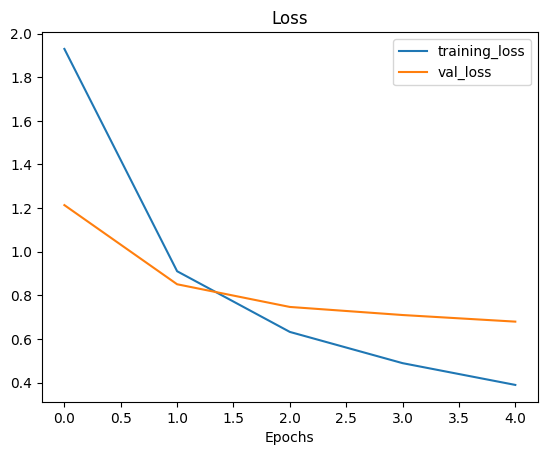

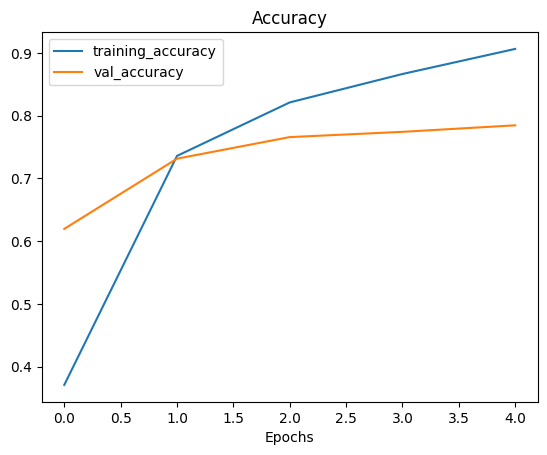

In [ ]:
plot_loss_curves(resnet_history)

And what about a summary of our model?

In [ ]:
# Resnet summary
resnet_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 feature_extraction_layer (  (None, 2048)              23564800  
 KerasLayer)                                                     
                                                                 
 output_layer (Dense)        (None, 10)                20490     
                                                                 
Total params: 23585290 (89.97 MB)
Trainable params: 20490 (80.04 KB)
Non-trainable params: 23564800 (89.89 MB)
_________________________________________________________________


A TensorFlow Hub teljesítményét itt tekintheti meg. A jellemzőkinyerő réteg 23 564 800 paraméterrel rendelkezik, amelyek előre megtanult minták, amelyeket a modell már megtanult az ImageNet adathalmazon. Mivel a `trainable=False` értéket állítottuk be, ezek a minták a képzés során befagyasztva maradnak (nem taníthatóak).

Ez azt jelenti, hogy a modell a képzés során a kimeneti rétegben lévő 20 490 paramétert frissíti a mi adatállományunknak megfelelően.

Oké, betanítottunk egy ResNetV250 modellt, ideje ugyanezt megtenni az EfficientNetB0 modellel.

A beállítás pontosan ugyanaz lesz, mint korábban, kivéve a `model_url` paramétert a `create_model()` függvényben.

In [ ]:
# EfficientNetB0 modell létrehozása
efficientnet_model = create_model(
    model_url_or_path=efficientnet_url,
    num_classes=train_data_10_percent.num_classes
)

# Modell lefordítása
efficientnet_model.compile(
    loss='categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(),
    metrics=['accuracy']
)

# EfficientNet modell tanítása (5 epocha az igazságos összehasonlításért a ResNet-tel)
efficientnet_history = efficientnet_model.fit(
    train_data_10_percent,
    epochs=5,
    steps_per_epoch=len(train_data_10_percent),
    validation_data=test_data,
    validation_steps=len(test_data)
)


Epoch 1/5
24/24 [==============================] - 24s 658ms/step - loss: 1.8635 - accuracy: 0.4253 - val_loss: 1.3163 - val_accuracy: 0.7312
Epoch 2/5
24/24 [==============================] - 14s 591ms/step - loss: 1.0592 - accuracy: 0.7747 - val_loss: 0.8709 - val_accuracy: 0.8180
Epoch 3/5
24/24 [==============================] - 14s 591ms/step - loss: 0.7489 - accuracy: 0.8293 - val_loss: 0.7003 - val_accuracy: 0.8436
Epoch 4/5
24/24 [==============================] - 13s 560ms/step - loss: 0.6059 - accuracy: 0.8627 - val_loss: 0.6145 - val_accuracy: 0.8544
Epoch 5/5
24/24 [==============================] - 14s 600ms/step - loss: 0.5109 - accuracy: 0.8933 - val_loss: 0.5617 - val_accuracy: 0.8616


Szent ég! Az EfficientNetB0 modell még jobban teljesít, mint a ResNetV250 modell! Több mint 85%-os pontosságot ér el a tesztkészleten... ismét **a képzési adatok mindössze 10%-ával**.

Milyen király ez?

Néhány sornyi kóddal képesek vagyunk kihasználni a legmodernebb modelleket, és a saját felhasználási esetünkhöz igazítani őket.

Nézzük meg a veszteséggörbéket.

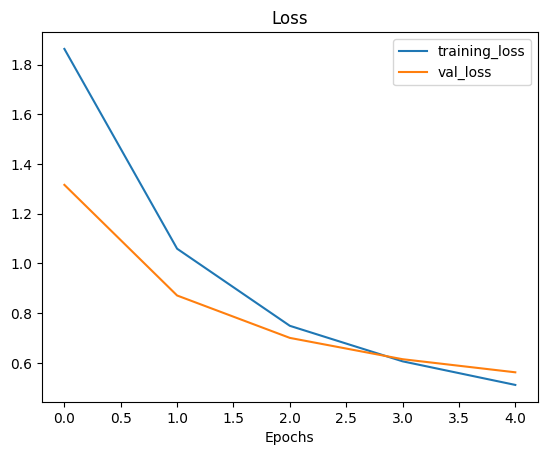

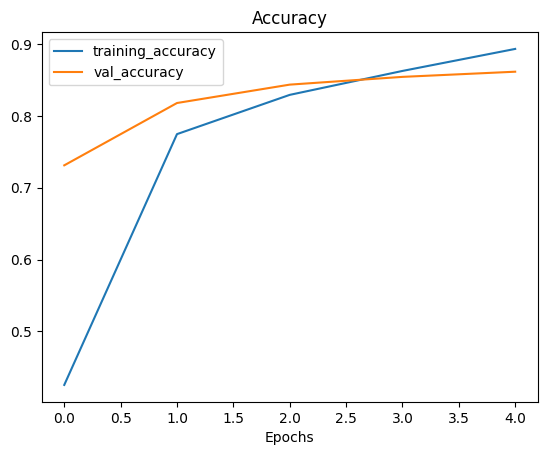

In [ ]:
plot_loss_curves(efficientnet_history)

Az EfficientNetB0 modell veszteséggörbéi alapján úgy tűnik, hogy ha tovább tanítanánk a modellünket, még tovább javulhatna. Talán ezt ki is próbálhatná?

Nézzük meg a modell összefoglalóját.

In [ ]:
efficientnet_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 feature_extraction_layer (  (None, 1280)              4049564   
 KerasLayer)                                                     
                                                                 
 output_layer (Dense)        (None, 10)                12810     
                                                                 
Total params: 4062374 (15.50 MB)
Trainable params: 12810 (50.04 KB)
Non-trainable params: 4049564 (15.45 MB)
_________________________________________________________________


Úgy tűnik, hogy annak ellenére, hogy több mint ötször kevesebb paraméterrel rendelkezik (4 049 564 vs. 23 564 800), mint a ResNet50V2 extrakciós réteg, az EfficientNetB0 jellemző extrakciós réteg jobb teljesítményt nyújt. Most már világos, honnan származik a "hatékony" elnevezés.

## 📖 Olvasnivaló

* Olvassa át a [TensorFlow Transfer Learning Guide](https://www.tensorflow.org/tutorials/images/transfer_learning) című dokumentumot, és határozza meg saját szavaival a transzfer tanulás két fő típusát.
* Nézd végig a [Transfer Learning with TensorFlow Hub tutorial](https://www.tensorflow.org/tutorials/images/transfer_learning_with_hub) című részt.